# OASIS INFOBYTE Internship
## Task 4: Email Spam Detection with Machine Learning

**Objective:** To build a machine learning model that classifies messages as spam or ham (legitimate messages) using Natural Language Processing (NLP).

**Author:** Vasuki S

### 1. Importing Libraries

The required Python libraries are imported for data handling, text preprocessing, data visualisation, TF-IDF feature extraction, model training and performance evaluation.

In [16]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.corpus import stopwords
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

nltk.download('stopwords')

print("Libraries imported successfully!")

Libraries imported successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### 2. Loading the Dataset

The SMS Spam Collection dataset is loaded into a Pandas DataFrame. It contains messages labelled as spam or ham, which will be used to train and evaluate the classification models.

In [17]:
df = pd.read_csv(
    '/content/SMSSpamCollection',
    sep='\t',
    header=None,
    names=['label', 'message']
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### 3. Data Cleaning and Understanding

The dataset is checked for missing values and duplicate records. Duplicate rows are removed to improve data quality before further analysis.

In [18]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("\nDataset shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

Missing Values:
label      0
message    0
dtype: int64

Duplicate Rows: 403

Dataset shape after removing duplicates: (5169, 2)
Remaining duplicates: 0


### 4. Class Distribution Analysis

The distribution of spam and ham messages is analysed by calculating their counts and percentages. A bar chart is created to visualise the class distribution and identify any imbalance in the dataset.

Spam and Ham Distribution:


,Count,Percentage
label,,
ham,4516,87.37
spam,653,12.63


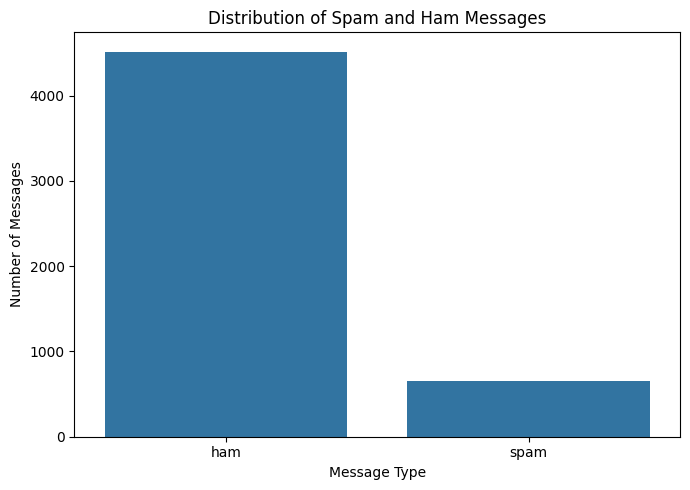

In [19]:
# Count spam and ham messages
label_counts = df['label'].value_counts()
label_percentages = df['label'].value_counts(normalize=True) * 100

distribution = pd.DataFrame({
    'Count': label_counts,
    'Percentage': label_percentages.round(2)
})

print("Spam and Ham Distribution:")
display(distribution)

# Visualise class distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='label')
plt.title('Distribution of Spam and Ham Messages')
plt.xlabel('Message Type')
plt.ylabel('Number of Messages')
plt.tight_layout()
plt.show()

### 5. Text Preprocessing

Text preprocessing converts messages into a consistent format for machine learning. The messages are converted to lowercase, punctuation and numbers are removed, and common English stopwords are removed to prepare the text for feature extraction.

In [20]:
# Load English stopwords
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return ' '.join(words)

# Apply preprocessing
df['cleaned_message'] = df['message'].apply(preprocess_text)

# Display original and cleaned messages
display(df[['message', 'cleaned_message']].head(10))

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goes usf lives around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling week word back like fun st...
6,Even my brother is not like to speak with me. ...,even brother like speak treat like aids patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile months u r entitled update latest colou...


### 6. Feature Extraction Using TF-IDF

TF-IDF (Term Frequency–Inverse Document Frequency) converts text into numerical features. It gives importance to words based on how frequently they appear in a message and how informative they are across all messages. These numerical features are used by machine learning models for classification.

In [21]:
# Separate input messages and target labels
X = df['cleaned_message']
y = df['label'].map({'ham': 0, 'spam': 1})

# Convert text into TF-IDF features
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(X)

print("TF-IDF feature extraction completed!")
print("Feature matrix shape:", X_tfidf.shape)
print("Number of unique words:", len(tfidf.get_feature_names_out()))

TF-IDF feature extraction completed!
Feature matrix shape: (5169, 7623)
Number of unique words: 7623


### 7. Splitting the Dataset

The dataset is divided into training and testing sets. The training set is used to train the machine learning models, while the testing set is used to evaluate their performance on unseen messages. An 80:20 split is used.

In [22]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training and testing split completed!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training and testing split completed!
Training samples: 4135
Testing samples: 1034


### 8. Training Machine Learning Models

Two classification algorithms, Multinomial Naive Bayes and Logistic Regression, are trained using the TF-IDF features. Their performance will be compared to identify the more effective model for spam detection.

In [23]:
# Train Multinomial Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)

# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


### 9. Model Evaluation

The trained models are evaluated using accuracy, precision, recall and F1-score. Confusion matrices are also used to compare correct and incorrect predictions for spam and ham messages.

Model Evaluation Results:


,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.9652,1.000,0.7252,0.8407
1,Logistic Regression,0.9497,0.954,0.6336,0.7615


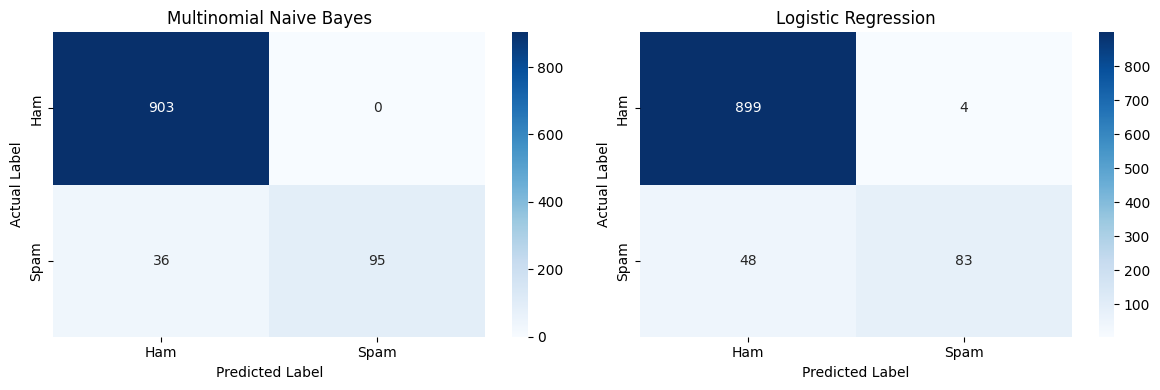

In [24]:
# Generate predictions
nb_predictions = nb_model.predict(X_test)
lr_predictions = lr_model.predict(X_test)

# Calculate evaluation metrics
models = {
    'Multinomial Naive Bayes': nb_predictions,
    'Logistic Regression': lr_predictions
}

results = []

for model_name, predictions in models.items():
    results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1-Score': f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
display(results_df.round(4))

# Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (model_name, predictions) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, predictions)
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Ham', 'Spam'],
        yticklabels=['Ham', 'Spam'],
        ax=ax
    )
    ax.set_title(model_name)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

### 10. Importance of Recall in Spam Detection

Recall is particularly important in spam detection because it measures the proportion of actual spam messages correctly identified by the model. Low recall means that many spam messages are incorrectly classified as legitimate messages (ham). These missed spam messages may reach the user's inbox. Therefore, a high recall helps reduce the number of spam messages that go undetected, while precision helps control the number of legitimate messages incorrectly marked as spam.

### 11. WordCloud Visualisation

Word clouds display frequently occurring words in spam and ham messages. They help visualise differences in the vocabulary used in unwanted and legitimate messages.

In [25]:
# Load English stopwords and add common SMS terms
stop_words = set(stopwords.words('english'))
stop_words.update([
    'u', 'ur', 'im', 'dont', 'ill', 'ive', 'youre',
    'txt', 'gt', 'lt', 'amp', 'ok', 'oh'
])

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)

    words = text.split()
    words = [word for word in words if word not in stop_words and len(word) > 1]

    return ' '.join(words)

df['cleaned_message'] = df['message'].apply(preprocess_text)

display(df[['message', 'cleaned_message']].head(10))

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis great wo...
1,Ok lar... Joking wif u oni...,lar joking wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,dun say early hor already say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goes usf lives around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling week word back like fun st...
6,Even my brother is not like to speak with me. ...,even brother like speak treat like aids patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...
8,WINNER!! As a valued network customer you have...,winner valued network customer selected receiv...
9,Had your mobile 11 months or more? U R entitle...,mobile months entitled update latest colour mo...


### 13. Testing with New Messages

The trained Multinomial Naive Bayes model is tested using multiple new messages that are not part of the training dataset. The messages are preprocessed and converted into TF-IDF features before being classified as spam or ham. This demonstrates how the model predicts the category of unseen messages.

In [26]:
# Sample messages not intentionally copied from the dataset
sample_messages = [
    "Congratulations! You have won a free prize. Call now to claim your reward!",
    "URGENT! Claim your cash reward before the offer expires!",
    "You have been selected for a special gift. Call now!",
    "Free entry available today. Text WIN to receive your prize!",
    "Limited offer! Claim your free voucher immediately!",
    "Hey, are we meeting at college tomorrow?",
    "Please send me the notes after class.",
    "I will call you when I reach home.",
    "Are you coming to class today?",
    "Thank you for helping me with the assignment."
]

# Preprocess the messages
cleaned_samples = [
    preprocess_text(message) for message in sample_messages
]

# Convert messages using the existing TF-IDF vectorizer
sample_features = tfidf.transform(cleaned_samples)

# Predict using the trained Naive Bayes model
predictions = nb_model.predict(sample_features)
spam_probabilities = nb_model.predict_proba(sample_features)[:, 1]

# Display results
prediction_results = pd.DataFrame({
    'Message': sample_messages,
    'Predicted Label': [
        'Spam' if prediction == 1 else 'Ham'
        for prediction in predictions
    ],
    'Spam Probability (%)': (
        spam_probabilities * 100
    ).round(2)
})

display(prediction_results)

,Message,Predicted Label,Spam Probability (%)
0,Congratulations! You have won a free prize. Ca...,Spam,95.63
1,URGENT! Claim your cash reward before the offe...,Spam,96.13
2,You have been selected for a special gift. Cal...,Ham,33.95
3,Free entry available today. Text WIN to receiv...,Spam,73.07
4,Limited offer! Claim your free voucher immedia...,Spam,81.78
5,"Hey, are we meeting at college tomorrow?",Ham,0.57
6,Please send me the notes after class.,Ham,6.75
7,I will call you when I reach home.,Ham,2.01
8,Are you coming to class today?,Ham,0.44
9,Thank you for helping me with the assignment.,Ham,6.43


### 14. Final Project Validation

The project is validated by checking the dataset quality, the trained classifiers, their evaluation metrics and the predictions generated for new messages. This confirms that the main stages of the spam detection project have been completed.

In [27]:
print("FINAL PROJECT VALIDATION")
print("-" * 35)

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nModels trained:", list(models.keys()))
print("\nModel evaluation:")
display(results_df.round(4))

print("\nNew messages tested:", len(prediction_results))
print("Predictions generated:",
      prediction_results['Predicted Label'].notna().all())

checks_passed = (
    df.isnull().sum().sum() == 0
    and df.duplicated().sum() == 0
    and len(models) >= 2
    and len(prediction_results) == 10
    and prediction_results['Predicted Label'].notna().all()
    and results_df[['Accuracy', 'Precision', 'Recall', 'F1-Score']]
        .notnull().all().all()
)

print("\nStatus:", "PASSED" if checks_passed else "CHECK REQUIRED")

FINAL PROJECT VALIDATION
-----------------------------------
Dataset shape: (5169, 3)
Missing values: 0
Duplicate rows: 0

Models trained: ['Multinomial Naive Bayes', 'Logistic Regression']

Model evaluation:


,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.9652,1.000,0.7252,0.8407
1,Logistic Regression,0.9497,0.954,0.6336,0.7615



New messages tested: 10
Predictions generated: True

Status: PASSED


### 14. Conclusion

This project developed a spam detection system using Natural Language Processing and machine learning. The SMS Spam Collection dataset was cleaned and preprocessed, and TF-IDF was used to convert text messages into numerical features. Multinomial Naive Bayes and Logistic Regression were trained and evaluated using accuracy, precision, recall, F1-score and confusion matrices. WordClouds were also created to visualise frequently occurring words in spam and ham messages. Based on the evaluation results, Multinomial Naive Bayes performed better overall on the test dataset.